In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv("Forwards Dataframe.csv")

In [3]:
df['Goal Scoring Efficiency'] = df['Non-Penalty Goals'] - df['Non-Penalty xG']

In [4]:
def categorize_goal_scoring_efficiency(row):
    if row['Goal Scoring Efficiency'] > 0:
        return 'Overperformer'
    elif row['Goal Scoring Efficiency'] < 0:
        return 'Underperformer'
    else:
        return 'Neutral'

In [5]:
df['Goal Scoring Efficiency Category'] = df.apply(categorize_goal_scoring_efficiency, axis=1)

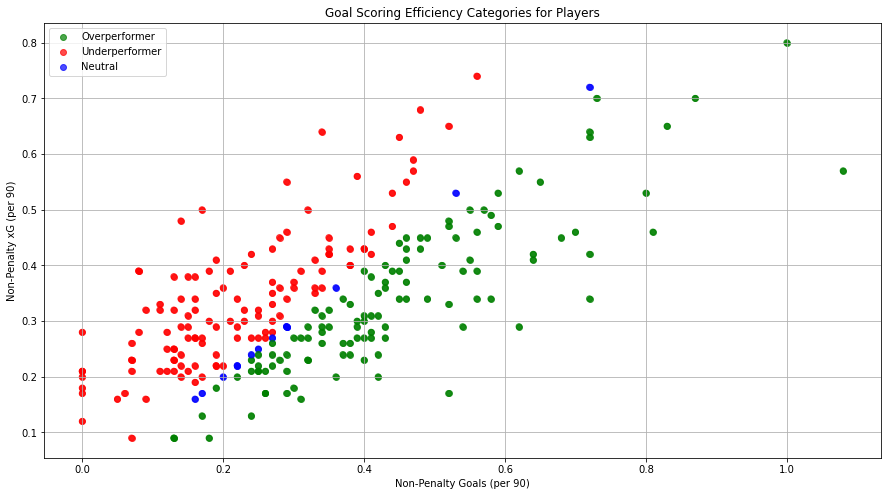

In [6]:
plt.figure(figsize=(15, 8))
colors = {'Overperformer': 'green', 'Underperformer': 'red', 'Neutral': 'blue'}

for category, color in colors.items():
    category_data = df[df['Goal Scoring Efficiency Category'] == category]
    plt.scatter(category_data['Non-Penalty Goals'], category_data['Non-Penalty xG'], c=color, label=category, alpha=0.7)

plt.scatter(df['Non-Penalty Goals'], df['Non-Penalty xG'], c=df['Goal Scoring Efficiency Category'].apply(lambda x: colors[x]), alpha=0.7)
plt.xlabel('Non-Penalty Goals (per 90)')
plt.ylabel('Non-Penalty xG (per 90)')
plt.title('Goal Scoring Efficiency Categories for Players')
plt.legend(colors.keys())
plt.grid(True)
plt.show()